In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
transactions = pd.read_excel('./transactions.xlsx')
vehicles = {
    "SharedBike": 1000,
    "SharedCar": 500,
    "SharedKickScooter": 700,
    "SharedScooter": 500
}

In [3]:
transactions.columns

Index(['Unnamed: 0.1', 'Unnamed: 0', 'vehicle_id', 'origin', 'destination',
       'time_start', 'time_end', 'price', 'distance', 'duration', 'wait_time',
       'energy_consumption', 'selected_vehicle_mode', 'state', 'SharedScooter',
       'SharedKickScooter', 'SharedCar', 'SharedBike', 'hour'],
      dtype='object')

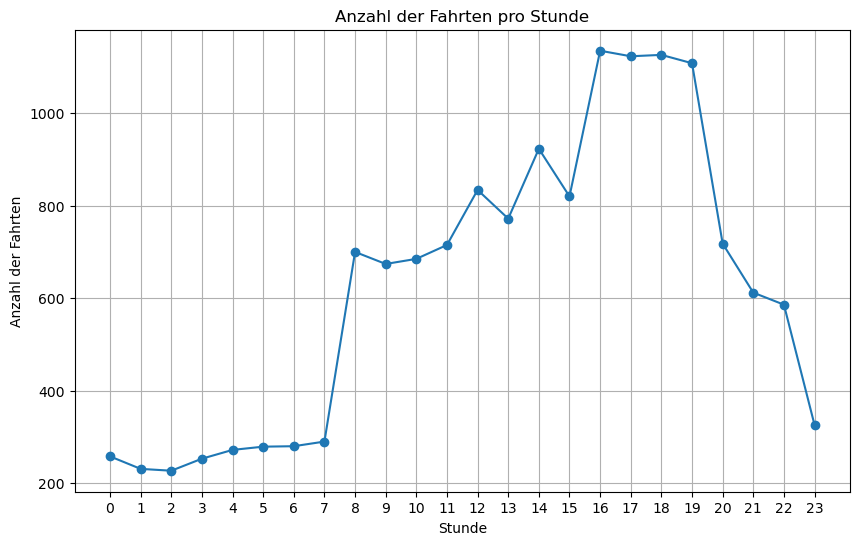

In [4]:
transactions['hour'] = transactions['time_start'] // 60
trips_per_hour = transactions.groupby('hour').size().reset_index(name='num_trips')

hours = range(24)
trips_per_hour = trips_per_hour.merge(pd.DataFrame({'hour': hours}), on='hour', how='right').fillna(0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(trips_per_hour['hour'], trips_per_hour['num_trips'], marker='o')
plt.title('Anzahl der Fahrten pro Stunde')
plt.xlabel('Stunde')
plt.ylabel('Anzahl der Fahrten')
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

## General Metrics

In [5]:
from metrics import MetricsFactory

metrics_factory = MetricsFactory(transactions)

general_metrics = metrics_factory.general_metrics


In [6]:

metrics_factory.print_simulation_summary(
    vehicles, {'SharedCar': 0.40, 'SharedScooter': 0.20, 'SharedKickScooter': 0.20, 'SharedBike': 0.10}, {'SharedCar': 0.414, 'SharedScooter': 0.126, 'SharedKickScooter': 0.202, 'SharedBike': 0.118})


########################################
############ Simulation Summary ############
 

#--------General Metrics--------
 
#  Num. Trips: 14947 
#  Num. Ful. Trips: 12167 
#  Num. Miss. Trips: 2780 
#  Num. Ful. Rate: 0.8140095002341607 
#  Distance: 60226596.149318606 
 
----------------------------------------

#--------Service Provider Metrics--------
 
#  Avg. Fleet. Utilization: 0.1731172839506173 
#  Fleet Profit: -24464492.662143163 
 
----------------------------------------

#--------Customer Metrics--------
 
#  Travel Time: 606810.2706970291 
#  Waiting Time: 51504.53661247463 
#  Costs: 91861.00206386145 
 
----------------------------------------

#--------Society Metrics--------
 
#  Co2 Emissions: 9322104.09405259 
 
----------------------------------------
 
########################################


## Service Provider Metrics

In [7]:
service_provider_metrics = metrics_factory.service_provider_metrics

### Utilization

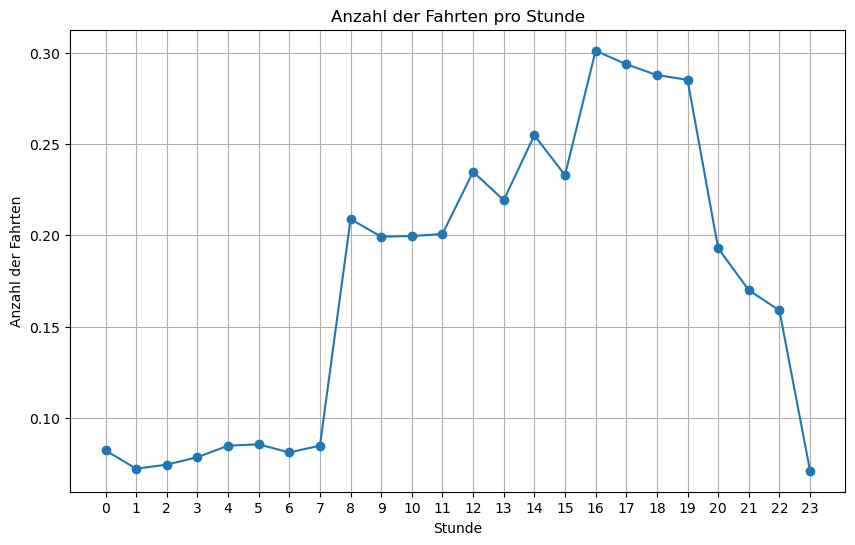

In [8]:
total_utilization_per_hour = service_provider_metrics.get_fleet_utilization(vehicles)

plt.figure(figsize=(10, 6))
plt.plot(total_utilization_per_hour, marker='o')
plt.title('Anzahl der Fahrten pro Stunde')
plt.xlabel('Stunde')
plt.ylabel('Anzahl der Fahrten')
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

### Fleet Costs

In [9]:
cost_per_vehicle_km = {'SharedCar': 0.53, 'SharedScooter': 0.53, 'SharedKickScooter': 0.53, 'SharedBike': 0.53}
service_provider_metrics.get_fleet_cost(cost_per_vehicle_km)

selected_vehicle_mode
SharedBike           9.175579e+06
SharedCar            6.303790e+06
SharedKickScooter    1.375366e+06
SharedScooter        7.701619e+06
Name: trip_costs, dtype: float64

### Fleet Revenue

In [10]:
cost_per_vehicle_km = {'SharedCar': 0.53, 'SharedScooter': 0.53, 'SharedKickScooter': 0.53, 'SharedBike': 0.53}
service_provider_metrics.get_fleet_profit(cost_per_vehicle_km)

selected_vehicle_mode
SharedBike          -9.146111e+06
SharedCar           -6.277608e+06
SharedKickScooter   -1.364097e+06
SharedScooter       -7.676677e+06
dtype: float64

## Customer Metrics

In [11]:
customer_metrics = metrics_factory.customer_metrics

### Waiting Time

In [12]:
wait_time = customer_metrics.get_avg_waiting_time()
print(f"Avg. Wait Time: {wait_time}")

Avg. Wait Time: 4.20297413866565


## Society Metrics

In [13]:
society_metrics = metrics_factory.society_metrics

### Co2 Emissions

In [14]:
co2_per_km_per_vehicle = {'SharedCar': 0.414, 'SharedScooter': 0.126, 'SharedKickScooter': 0.202, 'SharedBike': 0.118}

print(society_metrics.get_co2_emissions(co2_per_km_per_vehicle))

selected_vehicle_mode
SharedBike           2.042865e+06
SharedCar            4.924092e+06
SharedKickScooter    5.241962e+05
SharedScooter        1.830951e+06
Name: trip_emissions, dtype: float64
